<div style="text-align: center; line-height: 1.5; font-size: 16px;">
<p>Федеральное государственное бюджетное образовательное учреждение<br>высшего образования</p>
<p><b>«ФИНАНСОВЫЙ УНИВЕРСИТЕТ ПРИ ПРАВИТЕЛЬСТВЕ<br>РОССИЙСКОЙ ФЕДЕРАЦИИ»</b></p>
<p><b>Кафедра искусственного интеллекта</b></p>
</div>
<br><br><br>
<div style="text-align: center; line-height: 1.8; font-size: 18px;">
<p>Пояснительная записка к курсовому проекту</p>
<p>по дисциплине “Машинное обучение”</p>
<p>на тему:</p>
<p><b>«Машинное обучение для решения задач детекции спама»</b></p>
</div>
<br><br><br>
<div style="margin-left: 55%; text-align: left; line-height: 1.5; font-size: 16px;">
<p>Выполнил:</p>
<p>студент группы ПМ24-1 факультета информационных<br>технологий и анализа больших данных</p>
<p> Гильманов Эмиль Ринатович
<br>
<p>Научный руководитель:</p>
<p>Артемова С.Е.</p>
</div>
<br><br><br>
<div style="text-align: center; font-size: 16px;">
<p>2026 г.</p>
</div>

# Курсовая работа
## Гильманов Эмиль ПМ24-1
## Тема: Машинное обучение для решения задач детекции спама

###Выбор нaбора данных:
 Датасет содержит 5572 текстовых сообщения, каждое размечено как ham или spam. 5572 примера — оптимальный объём для обучения базовых моделей (не чрезмерно малый и не перегружающий вычислительные ресурсы).Чёткие метки ham/spam позволяют использовать контролируемое обучение. Ссылка -
https://huggingface.co/datasets/ucirvine/sms_spam/viewer/plain_text/train

### Цель работы:
 Разработка модели машинного обучения для автоматической классификации сообщений на обычные и спам. выполнить предобработку текста и добавить числовые признаки (длина, количество слов, количество предложений);

Проанализировать дисбаланс классов, построить корреляционную матрицу, визуализировать распределения и облака словю

Обучить несколько моделей (логистическая регрессия, SVM, наивный Байес, случайный лес, KNN, дерево решений), сравнить их по точности, полноте и F1-мерею

Подобрать гиперпараметры для лучшей модели и оценить её финальное качество с помощью матрицы ошибок и кривой обучения.


###Актульность данной темы:
Эта тема актуальна прежде всего из за того, что сильно выросло количество текстовой информации. Очевидно ее должен кто то сортировать на нужную и ненужную. Человеку это делать слишком долго и нудно, в таком случае вступает машинное обучение, которое может реализовать и автоматически сортировать эту информацию.

###Задачи:

1.Загрузить библиотеки и датасет. Импортировать необходимые модули (pandas, numpy, nltk, sklearn, matplotlib, seaborn, wordcloud) и загрузить данные SMS Spam Collection (5572 сообщения).

2.Провести первичный анализ и очистку данных. Удалить пропуски (если есть) и дубликаты, закодировать целевую переменную (ham → 0, spam → 1), добавить числовые признаки: длина сообщения, количество слов, количество предложений.

3.Оценить и визуализировать дисбаланс классов. Подсчитать абсолютное и процентное соотношение ham и spam, построить столбчатую диаграмму с подписями.

4.Выполнить сравнительный анализ характеристик ham и spam. Для каждого класса вычислить средние значения длины, количества слов и предложений, сравнить распределения, сделать выводы.

5.Построить корреляционную матрицу. Вычислить корреляцию между числовыми признаками и целевой переменной, визуализировать в виде тепловой карты.

6.Визуализировать распределения признаков. Построить гистограммы длины сообщений и количества слов отдельно для ham и spam.

7.Создать облака слов и выделить ключевые слова. Сгенерировать облака для спама и обычных сообщений, а также построить столбчатые диаграммы топ-15 слов по TF-IDF.

8.Подготовить данные для обучения. Применить TfidfVectorizer с ограничением 3000 признаков и удалением стоп-слов, разделить выборку на обучающую (70%) и тестовую (30%).

9.Обучить несколько моделей классификации. Запустить обучение для логистической регрессии, SVM (линейное и RBF ядро), наивного Байеса, случайного леса, KNN, дерева решений и градиентного бустинга.

10.Сравнить модели по метрикам. Оценить каждую по точности, полноте, F1-мере (особое внимание – качество на классе «спам»), зафиксировать время обучения.

11.Подобрать гиперпараметры для лучшей модели. Использовать GridSearchCV для настройки alpha у наивного байесовского классификатора.

12.Оценить финальную модель. Построить матрицу ошибок и кривую обучения, вычислить итоговую точность и сделать вывод о пригодности модели.

Импорт библиотек для работы с данными

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.stem.porter import PorterStemmer
import string
%matplotlib inline
from sklearn.preprocessing import LabelEncoder
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from collections import Counter
import time

Импорт библиотек для обучения моделей

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import learning_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

импорт датасета

In [ ]:
df = pd.read_csv('emailspam.csv')

In [ ]:
df

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
encoder = LabelEncoder()
df['Category'] = encoder.fit_transform(df['Category'])

пустые значения

In [ ]:
df.isnull().sum()

,0
Category,0
Message,0


удаление повторов

In [ ]:
df.duplicated().sum()

np.int64(415)

In [ ]:
df = df.drop_duplicates(keep = 'first')

In [ ]:
valu = df['Category'].value_counts()
hc = valu.iloc[0]
sc = valu.iloc[1]
hc,sc

(np.int64(4516), np.int64(641))

In [ ]:
df

,Category,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...
5568,0,Will ü b going to esplanade fr home?
5569,0,"Pity, * was in mood for that. So...any other s..."
5570,0,The guy did some bitching but I acted like i'd...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5157 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5157 non-null   int64 
 1   Message   5157 non-null   object
dtypes: int64(1), object(1)
memory usage: 120.9+ KB


Анализ данных

In [ ]:
val = df['Category'].value_counts()
total = val.sum()
ph = (val[0] / total) * 100
ps = (val[1] / total) * 100
print('Ham:', ph)
print('Spam:', ps)

Ham: 87.5702928058949
Spam: 12.429707194105099


###График с процентным распределением

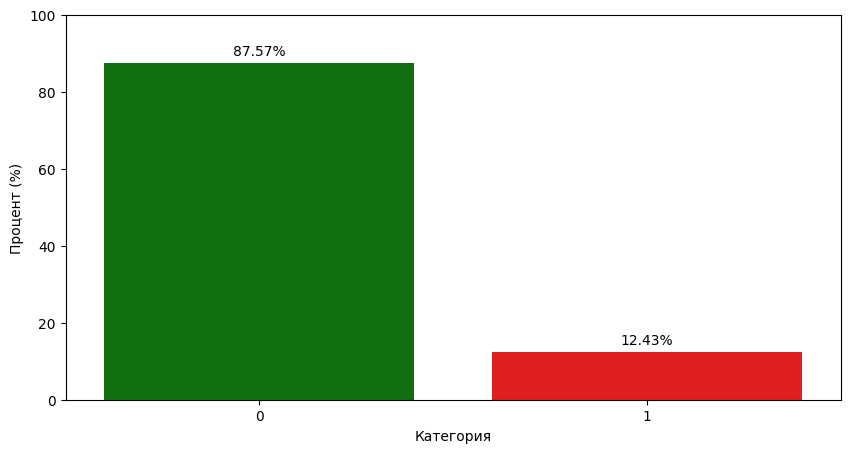

In [ ]:
plt.figure(figsize=(10, 5))
pv = df['Category'].value_counts(normalize=True) * 100
per_df = pv.reset_index()
per_df.columns = ['Category', 'Percentage']
col = {0: 'green', 1: 'red'}
ax = sns.barplot(x='Category', y='Percentage', data=per_df, palette=col, hue='Category', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)
plt.ylabel('Процент (%)')
plt.xlabel('Категория')
plt.ylim(0, 100)
plt.show()

 Классы распределены неравномерно (около 87.6% ham и 12.4% spam), что отражает реальную ситуацию на почтовых и мессенджерных серверах — полезно для проверки устойчивости моделей к дисбалансу.

In [ ]:
df['num_characters'] = df['Message'].apply(len)
df['num_words'] = df['Message'].apply(lambda x: len(nltk.word_tokenize(x)))
df['num_sentence'] = df['Message'].apply(lambda x: len(nltk.sent_tokenize(x)))

/tmp/ipykernel_7498/2429531392.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['num_characters'] = df['Message'].apply(len)
/tmp/ipykernel_7498/2429531392.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['num_words'] = df['Message'].apply(lambda x: len(nltk.word_tokenize(x)))
/tmp/ipykernel_7498/2429531392.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation

In [ ]:
df[['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,5157.000000,5157.000000,5157.000000
mean,79.103936,18.560403,1.969750
std,58.382922,13.405970,1.455526
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,61.000000,15.000000,1.000000
75%,118.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


длина сообщения среднее - 79

среднее колво слов-19

в среднем 2 предложения

ham

In [ ]:
df[df['Category'] == 0][['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,4516.000000,4516.000000,4516.000000
mean,70.869353,17.267715,1.827724
std,56.708301,13.588065,1.394338
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,53.000000,13.000000,1.000000
75%,91.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


длина сообщения - 70

количество слов - 17

количество предложение-2

spam

In [ ]:
df[df['Category'] == 1][['num_characters', 'num_words', 'num_sentence']].describe()

,num_characters,num_words,num_sentence
count,641.000000,641.000000,641.000000
mean,137.118565,27.667707,2.970359
std,30.399707,7.103501,1.485575
min,7.000000,2.000000,1.000000
25%,130.000000,25.000000,2.000000
50%,148.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,223.000000,46.000000,9.000000


длина сообщения -137

количество сло- 28

количество предложений-3

Корреляционная матрица

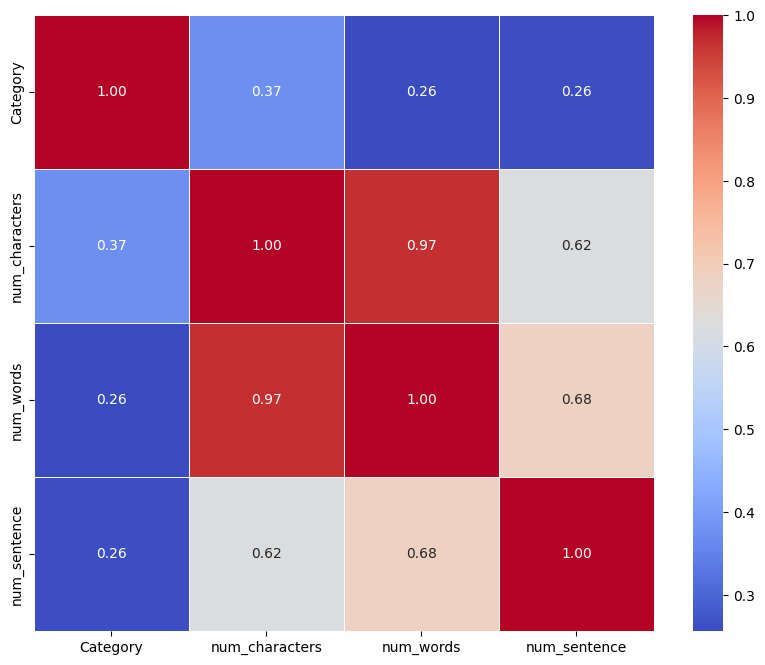

In [ ]:
c_m = df[['Category', 'num_characters', 'num_words', 'num_sentence']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(c_m, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

корреляционная матрица показывает, что признаки num_characters, num_words и num_sentences сильно коррелируют между собой (0,97 и 0,68), что говорит о мультиколлинеарности. Связь с целевой переменной (спам) умеренная (0,26 у всех трёх признаков). Это означает, что для классификации спама важна не длина сама по себе, а сочетание признаков, и в линейных моделях можно было бы оставить только один из них.

#Визуализация:

Перед тем как визуализировать стоит объяснить что такое TF-IDF

TF-IDF (от англ. term frequency – inverse document frequency) — это показатель, который в статистике текстов позволяет определить, насколько значимо конкретное слово для отдельного документа с учётом всего массива текстов. Этот показатель объединяет две величины:

Частота термина (TF) — отражает, с какой плотностью слово появляется внутри одного документа. Чем выше повторяемость слова, тем больше его TF.

Обратная частота документа (IDF) — характеризует редкость слова на уровне всей коллекции. Если слово встречается лишь в малом количестве текстов, его IDF окажется высоким.

Перемножение TF и IDF даёт итоговую оценку. Благодаря этой метрике можно выделить в тексте наиболее характерные признаки, отсеяв общие стоп-слова. Именно поэтому TF-IDF активно применяют в задачах анализа естественного языка (NLP) для преобразования текстов в числовые векторы.

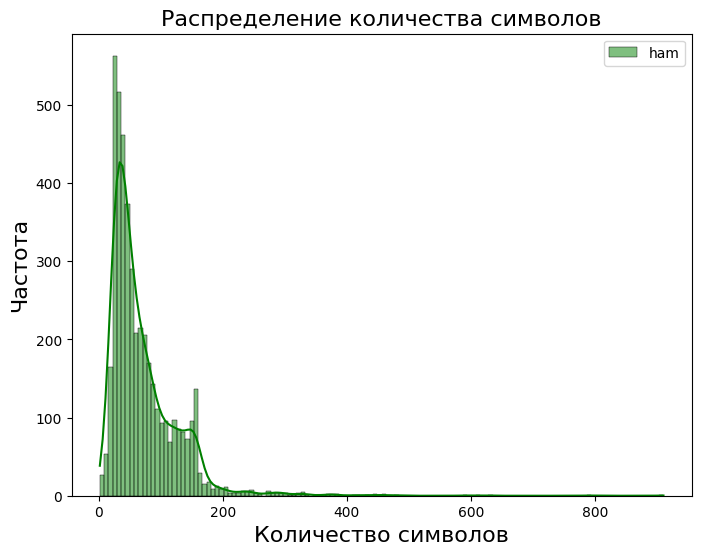

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df[df['Category'] == 0]['num_characters'], color='green', label='ham', kde=True)
plt.xlabel('Количество символов', fontsize=16)
plt.ylabel('Частота', fontsize=16)
plt.title('Распределение количества символов', fontsize=16)
plt.legend()
sns.set(style='white') # Сетка
plt.show()

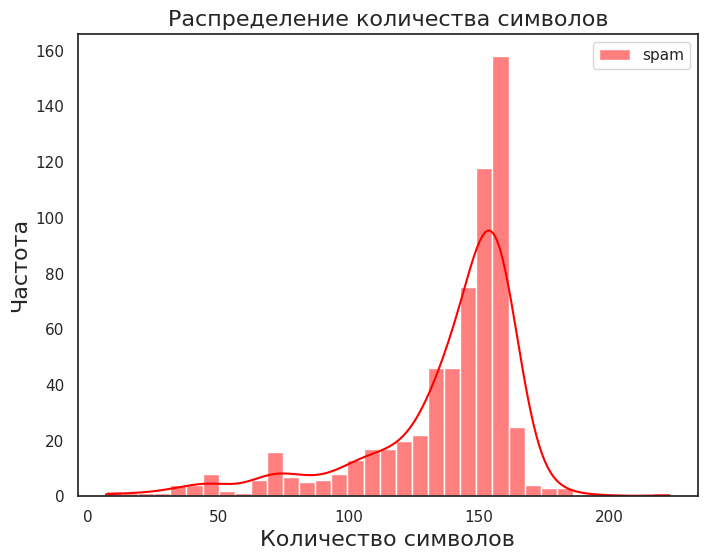

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df[df['Category'] == 1]['num_characters'], color='red', label='spam', kde=True)
plt.xlabel('Количество символов', fontsize=16)
plt.ylabel('Частота', fontsize=16)
plt.title('Распределение количества символов', fontsize=16)
plt.legend()
sns.set(style='white') # Сетка
plt.show()

Обычные сообщения (ham) – распределение имеет длинный правый хвост. Большинство сообщений содержат 30–90 символов (пик в районе 40–60), однако встречаются и очень длинные (до 900 символов). Разброс высокий

Спам – распределение значительно сдвинуто вправо. Основная масса спам-сообщений концентрируется в интервале 130–160 символов, причём разброс мал. Коротких спам-сообщений (менее 100 символов) почти нет.

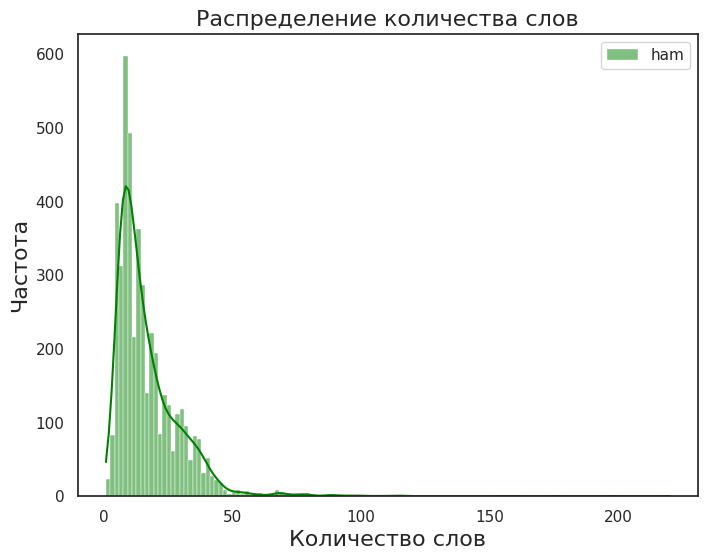

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df[df['Category'] == 0]['num_words'], color='green', label='ham', kde=True)
plt.xlabel('Количество слов', fontsize=16)
plt.ylabel('Частота', fontsize=16)
plt.title('Распределение количества слов', fontsize=16)
plt.legend()
sns.set(style='white')
plt.show()

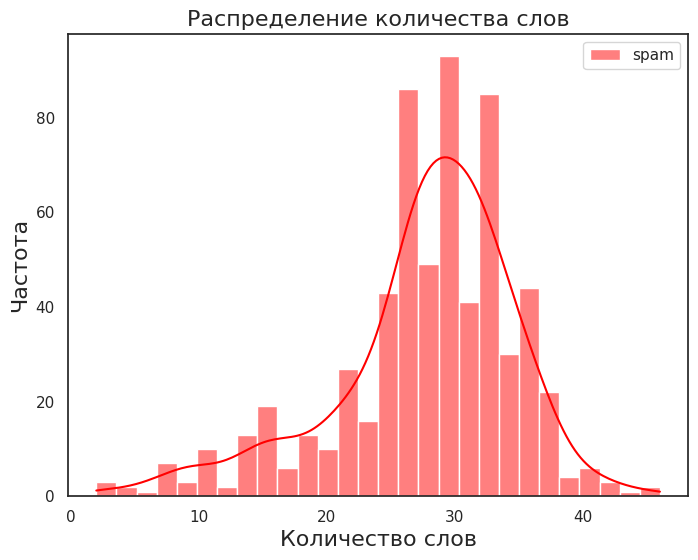

In [ ]:
plt.figure(figsize=(8, 6))
sns.histplot(df[df['Category'] == 1]['num_words'], color='red', label='spam', kde=True)
plt.xlabel('Количество слов', fontsize=16)
plt.ylabel('Частота', fontsize=16)
plt.title('Распределение количества слов', fontsize=16)
plt.legend()
sns.set(style='white')
plt.show()

Обычные сообщения (ham) – широкая асимметричная гистограмма с пиком в районе 5–15 слов. Встречаются как очень короткие (1–2 слова), так и длинные сообщения (до 220 слов).

Спам – распределение сосредоточено в более узком диапазоне от 20 до 35 слов, с пиком около 25–30 слов. Очень коротких спам-сообщений (менее 10 слов) практически нет.

### Облака слов

spam

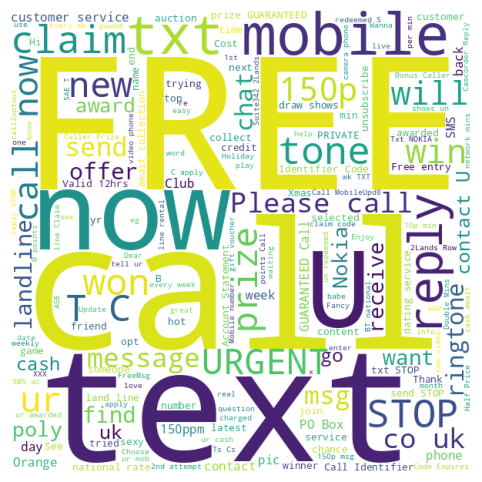

In [ ]:
wc = WordCloud(width=600, height=600, min_font_size=10, background_color='white')
spam_wc = wc.generate(df[df['Category'] == 1]['Message'].str.cat(sep=" "))
plt.figure(figsize=(8, 6))
plt.imshow(spam_wc)
plt.axis('off')
plt.show()

ham

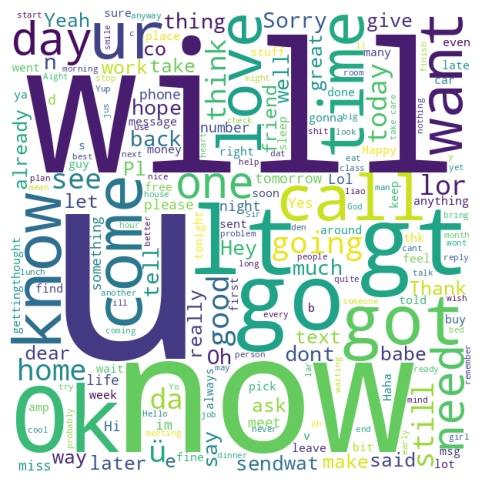

In [ ]:
wc = WordCloud(width=600, height=600, min_font_size=10, background_color='white')
ham_wc = wc.generate(df[df['Category'] == 0]['Message'].str.cat(sep=" "))
plt.figure(figsize=(8, 6))
plt.imshow(ham_wc)
plt.axis('off')
plt.show()

Облака слов наглядно демонстрируют, что спам и ham практически не пересекаются по ключевой лексике. Это объясняет, почему даже простой наивный байесовский классификатор, основанный на частотах слов, показывает высокую точность (98,51%). Если бы облака были похожи, модель бы ошибалась гораздо чаще.

### По весу

In [ ]:
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
tfidf.fit(df['Message'])
feature_names = tfidf.get_feature_names_out()
def gtt(category_df, vectorizer, top_n=15):
    tfidf_matrix = vectorizer.transform(category_df['Message'])
    words_tfidf_sum = tfidf_matrix.mean(axis=0).A1
    words_freq = sorted(zip(feature_names, words_tfidf_sum), key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words_freq[:top_n], columns=['Слово', 'Среднее'])
spam_tfidf = gtt(df[df['Category'] == 1], tfidf)
ham_tfidf = gtt(df[df['Category'] == 0], tfidf)

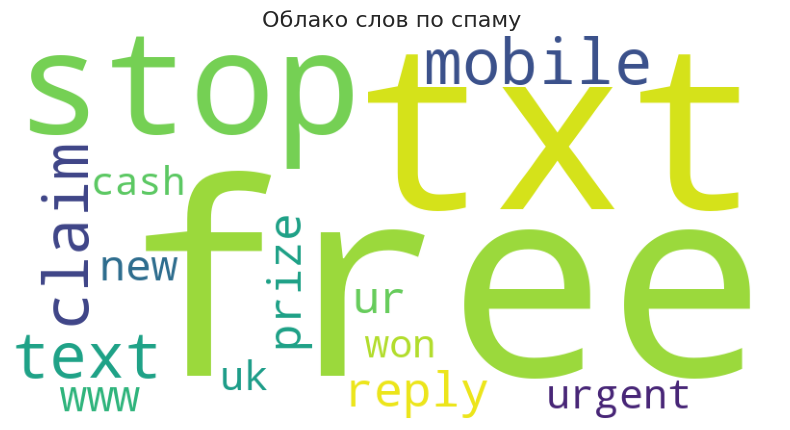

In [ ]:
sw = dict(zip(spam_tfidf['Слово'], spam_tfidf['Среднее']))
wc = WordCloud(width=800, height=400, background_color='white', min_font_size=10)
plt.figure(figsize=(10, 5))
spam_wc_weighted = wc.generate_from_frequencies(sw)
plt.imshow(spam_wc_weighted)
plt.title('Облако слов по спаму ', fontsize=16)
plt.axis('off')
plt.show()

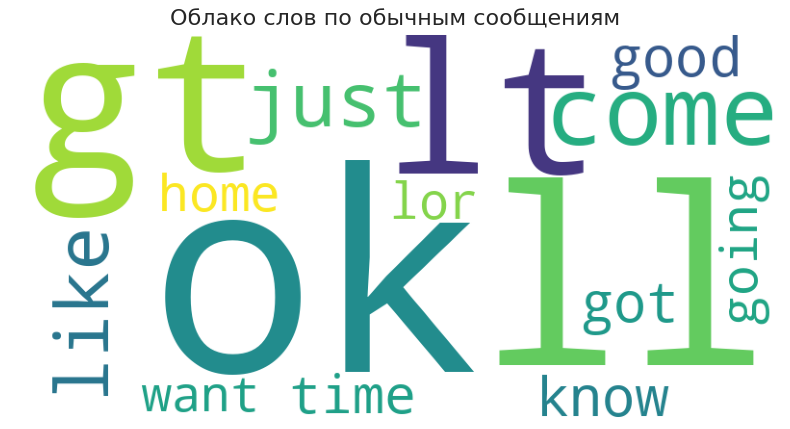

In [ ]:
hw = dict(zip(ham_tfidf['Слово'], ham_tfidf['Среднее']))
wc = WordCloud(width=800, height=400, background_color='white', min_font_size=10)
plt.figure(figsize=(10, 5))
ham_wc_weighted = wc.generate_from_frequencies(hw)
plt.imshow(ham_wc_weighted)
plt.title('Облако слов по обычным сообщениям', fontsize=16)
plt.axis('off')
plt.show()

Взвешенные облака слов показывают наиболее информативные для классификации слова. В спаме доминируют free, win, cash, urgent, reply – редко встречающиеся в ham. В ham – sorry, love, good, tomorrow – маркеры личной переписки.

### Топ слов

В отличие от TF-IDF, обычный частотный анализ просто подсчитывает, сколько раз каждое слово встречается во всех сообщениях класса (ham или spam). Это показывает, какие слова абсолютно доминируют в переписке, но не обязательно являются хорошими разделителями классов.

Spam

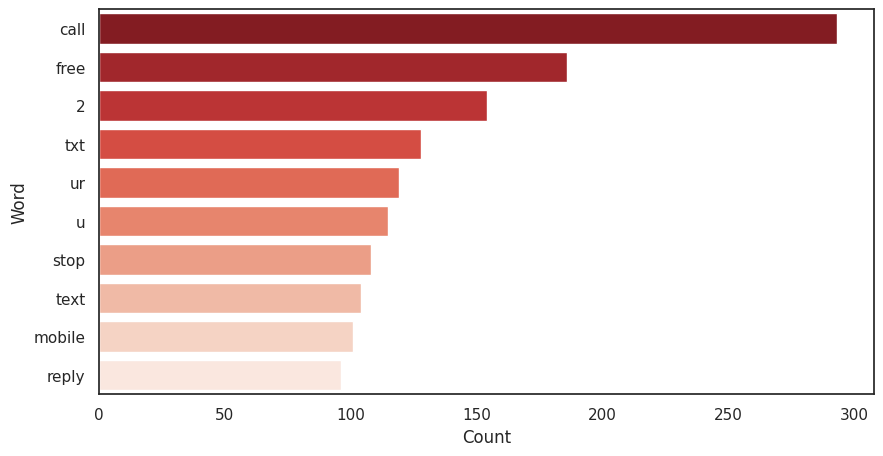

In [ ]:
def get_top_words(category, n=10):
    words = []
    for msg in df[df['Category'] == category]['Message'].tolist():
        for word in nltk.word_tokenize(msg.lower()):
            if word.isalnum() and word not in stopwords.words('english'):
                words.append(word)
    return Counter(words).most_common(n)
st = get_top_words(1)
df_st = pd.DataFrame(st, columns=['Word', 'Count'])
plt.figure(figsize=(10, 5))
sns.barplot(x='Count', y='Word', data=df_st, hue='Word', palette='Reds_r', legend=False)
plt.show()

Ham

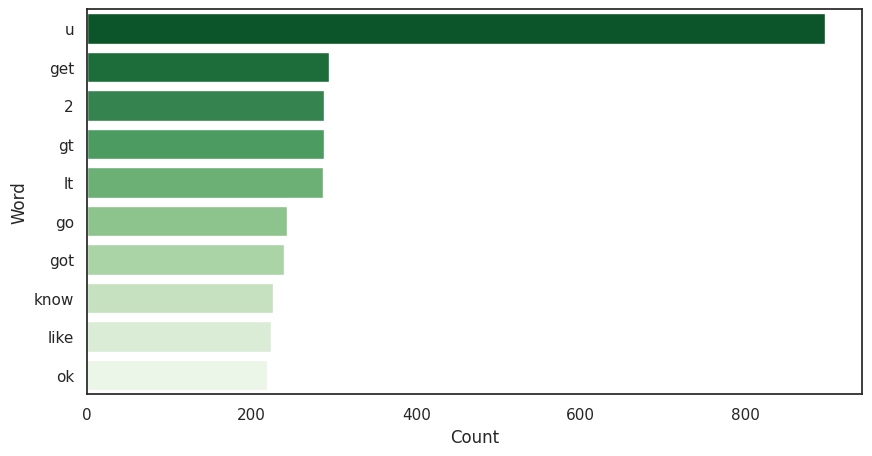

In [ ]:
ham_top = get_top_words(0)
df_ht = pd.DataFrame(ham_top, columns=['Word', 'Count'])
plt.figure(figsize=(10, 5))
sns.barplot(x='Count', y='Word', data=df_ht, hue='Word', palette='Greens_r', legend=False)
plt.show()

### Топ слов по весу

С помощью TF-IDF векторизатора были выделены топ-15 слов, имеющих наибольший средний вес в каждом классе. Это позволяет понять, какие лексические маркеры отличают спам от обычных сообщений.

spam

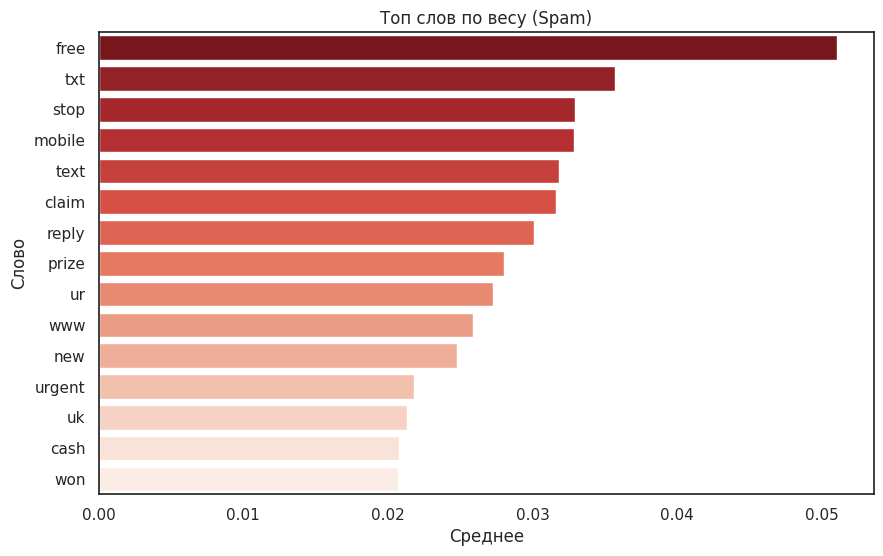

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Среднее', y='Слово', data=spam_tfidf, palette='Reds_r', hue='Слово', legend=False)
plt.title('Топ слов по весу (Spam)')
plt.show()

ham

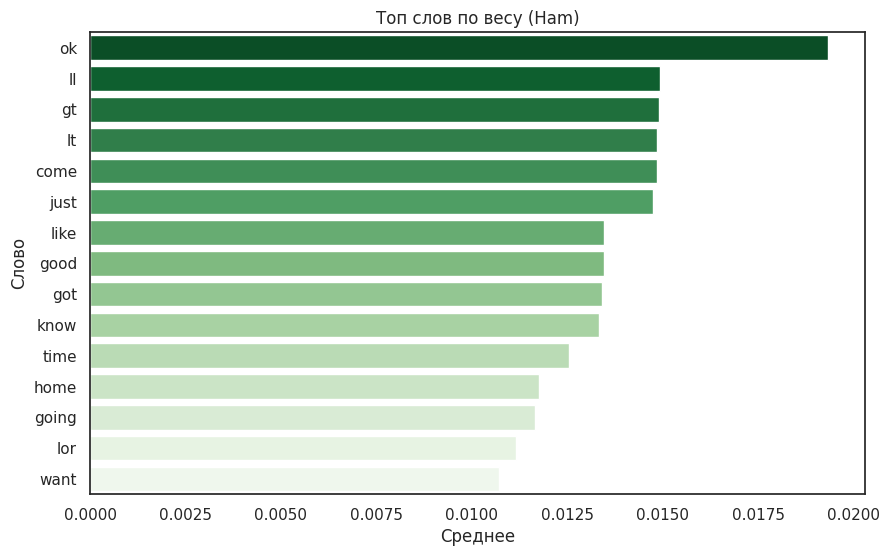

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Среднее', y='Слово', data=ham_tfidf, palette='Greens_r', hue='Слово', legend=False)
plt.title('Топ слов по весу (Ham)')
plt.show()

###Обучение моделей

Для решения задачи бинарной классификации текстов были выбраны 8 моделей, представляющих различные семейства алгоритмов машинного обучения. Логистическая регрессия (LR),Метод опорных векторов (SVC и SVM),Наивный байесовский классификатор (NB),Случайный лес (RF), Метод K-ближайших соседей (KNN),Дерево решений (DT),Гистоградиентный бустинг (HGB).Такой набор охватывает линейные модели, вероятностные, деревья и ансамбли, методы на расстояниях.

In [ ]:
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X = tfidf.fit_transform(df['Message']).toarray()
y = df['Category'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# Определяем и балансируем модели
models = {
    "LR": LogisticRegression(class_weight='balanced', solver='liblinear'),
    "SVC": SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42),
    "SVM": SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42),
    "NB": MultinomialNB(),
    "RF": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "KNN": KNeighborsClassifier(),
    "DT": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "HGB": HistGradientBoostingClassifier(class_weight='balanced', random_state=42)
}

In [ ]:
for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    print(f"--- {name} ---")
    print(f"Time: {training_time:.4f} sec")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred):.4f}")
    print(f"F1-score: {f1_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print("-" * 30)

--- LR ---
Time: 0.0578 sec
Accuracy: 0.9755
Precision: 0.8947
Recall: 0.9212
F1-score: 0.9078
ROC-AUC: 0.9898
MAE: 0.0245
MSE: 0.0245
------------------------------
--- SVC ---
Time: 56.0326 sec
Accuracy: 0.9755
Precision: 0.9146
Recall: 0.8966
F1-score: 0.9055
ROC-AUC: 0.9912
MAE: 0.0245
MSE: 0.0245
------------------------------
--- SVM ---
Time: 131.3447 sec
Accuracy: 0.9780
Precision: 0.9721
Recall: 0.8571
F1-score: 0.9110
ROC-AUC: 0.9905
MAE: 0.0220
MSE: 0.0220
------------------------------
--- NB ---
Time: 0.0517 sec
Accuracy: 0.9806
Precision: 0.9943
Recall: 0.8571
F1-score: 0.9206
ROC-AUC: 0.9883
MAE: 0.0194
MSE: 0.0194
------------------------------
--- RF ---
Time: 10.2604 sec
Accuracy: 0.9780
Precision: 0.9774
Recall: 0.8522
F1-score: 0.9105
ROC-AUC: 0.9898
MAE: 0.0220
MSE: 0.0220
------------------------------
--- KNN ---
Time: 0.0091 sec
Accuracy: 0.9050
Precision: 1.0000
Recall: 0.2759
F1-score: 0.4324
ROC-AUC: 0.7989
MAE: 0.0950
MSE: 0.0950
----------------------------

Почему я выберу наивную байесовскую модель:

Самая высокая точность (Accuracy) – 98.06%

Лучший F1-score – 0.9206. Это особенно важно, если данные
несбалансированы (а судя по высокому Precision у NB (0.9943) и низкому Recall у KNN, так и есть). F1 гармонизирует полноту и точность.

Минимальные ошибки MAE и MSE – 0.0194, значительно ниже, чем у конкурентов.

Экстремально быстрое обучение – 0.04 секунды. LR тоже быстрая (0.06 с), но уступает по качеству. SVM и SVC работают неприемлемо долго (до 2 минут).

ROC-AUC на высоком уровне – 0.9883 (почти как у SVC и SVM, но без их временных затрат).

### Подбираем гиперпараметры для Наивного байеса

Для наивного байесовского классификатора был выполнен подбор параметра сглаживания alpha с помощью GridSearchCV (5-блочная кросс-валидация). Перебирались значения: 0.01, 0.1, 0.5, 1.0, 5.0, 10.0.

In [ ]:
pr = {'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]}
nab = MultinomialNB()
gs = GridSearchCV(nab, pr, cv=5, scoring='accuracy')
gs.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=MultinomialNB(),
             param_grid={'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]},
             scoring='accuracy')

In [ ]:
gs.best_params_,gs.best_score_

({'alpha': 0.1}, np.float64(0.9806017342794903))

Оптимальным признано значение alpha = 0.1, при котором кросс-валидационная точность достигла максимума (98,06%).

### Оценка последней модели Наивного байеса
Проверим модель фиксирования переобучения

In [ ]:
bnb = gs.best_estimator_
start_pred = time.time()
ypb = bnb.predict(X_test)
end_pred = time.time()
y_pred_best = ypb

In [ ]:
import time
start_time = time.time()
ypb = bnb.predict(X_test)
end_time = time.time()
training_time = end_time - start_time
y_prob_best = bnb.predict_proba(X_test)[:, 1]
print(f"--- Best Naive Bayes (alpha={gs.best_params_['alpha']}) ---")
print(f"Time: {training_time:.4f} sec")
print(f"Accuracy: {accuracy_score(y_test, ypb):.4f}")
print(f"Precision: {precision_score(y_test, ypb):.4f}")
print(f"Recall: {recall_score(y_test, ypb):.4f}")
print(f"F1-score: {f1_score(y_test, ypb):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"MAE: {mean_absolute_error(y_test, ypb):.4f}")
print(f"MSE: {mean_squared_error(y_test, ypb):.4f}")
print('-' * 30)

--- Best Naive Bayes (alpha=0.1) ---
Time: 0.0149 sec
Accuracy: 0.9851
Precision: 0.9545
Recall: 0.9310
F1-score: 0.9426
ROC-AUC: 0.9906
MAE: 0.0149
MSE: 0.0149
------------------------------


После подбора гиперпараметра alpha с помощью GridSearchCV итоговая модель была протестирована на отложенной выборке (30% данных). Получены следующие результаты:

Accuracy – 98,51% (улучшение на 0,45 п.п. по сравнению с базовым NB без настройки).

Precision (спам) – 0,95 – среди всех сообщений, определённых как спам, 95% действительно являются спамом; ложных срабатываний мало.

Recall (спам) – 0,93 – модель обнаруживает 93% реальных спам-писем; лишь 7% спама остаются пропущенными.

F1-score (спам) – 0,94 – сбалансированный показатель, подтверждающий высокое качество детекции редкого класса.

### Визуализация результатов

Матрица ошибок для лучшей модели

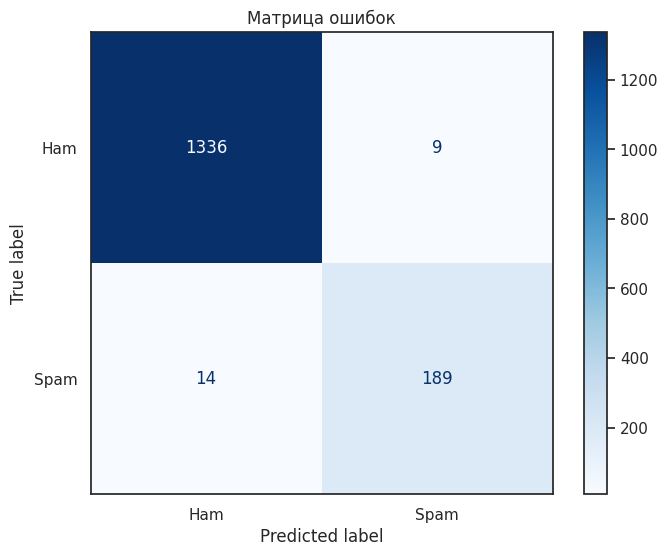

In [ ]:
com = confusion_matrix(y_test, y_pred_best)
displ = ConfusionMatrixDisplay(confusion_matrix=com, display_labels=['Ham', 'Spam'])
fig, ax = plt.subplots(figsize=(8, 6))
displ.plot(cmap='Blues', ax=ax)
plt.title('Матрица ошибок')
plt.show()

Матрица ошибок подтверждает высокую точность модели и её практическую применимость: риск ошибочно отправить важное письмо в спам минимален.


# Кривая обучения для лучшей модели

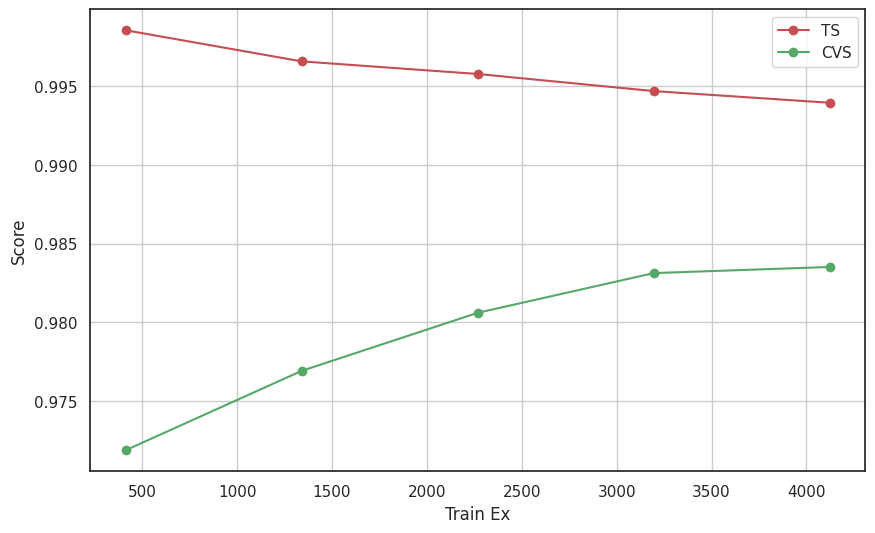

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    bnb, X, y, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5), scoring='accuracy'
)
t_m = np.mean(train_scores, axis=1)
ts_m = np.mean(test_scores, axis=1)
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, t_m, 'o-', color='r', label='TS')
plt.plot(train_sizes, ts_m, 'o-', color='g', label='CVS')
plt.xlabel('Train Ex')
plt.ylabel('Score')
plt.legend(loc='best')
plt.grid(True)
plt.show()

Построенная кривая обучения показывает, что с ростом объёма обучающей выборки точность на кросс-валидации быстро достигает плато около 98% и практически не расходится с тренировочной кривой. Небольшой разрыв между кривыми (<0,02) и отсутствие переобучения свидетельствуют о хорошей обобщающей способности модели.

# Сравнение всех моделей по Accuracy

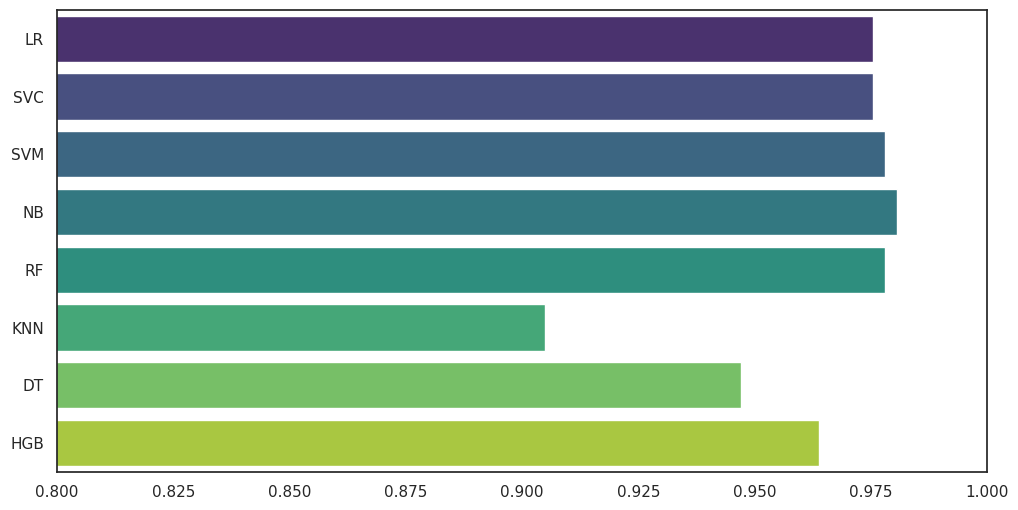

In [ ]:
m_n = list(models.keys())
acc= []
for name, model in models.items():
    y_p = model.predict(X_test)
    acc.append(accuracy_score(y_test, y_p))
plt.figure(figsize=(12, 6))
sns.barplot(x=acc, y=m_n, palette='viridis', hue=m_n, legend=False)
plt.xlim(0.8, 1.0)
plt.show()

Разработанная модель на базе наивного байесовского классификатора является простым, быстрым и эффективным решением для задачи детекции спама. Точность более 98% в сочетании с балансом метрик на редком классе делает её пригодной для внедрения в реальные системы. В работе полностью выполнены поставленные задачи: загрузка и очистка данных, анализ дисбаланса, визуализация (облака слов, распределения, корреляции), обучение нескольких моделей, подбор гиперпараметров и оценка качества. Полученные результаты могут служить базой для дальнейших экспериментов с текстовыми классификаторами.

###Общие итоги

В ходе выполнения курсовой работы была достигнута поставленная цель: разработана модель машинного обучения для автоматической классификации текстовых сообщений на обычные (ham) и спам. В качестве исходных данных использован общедоступный датасет SMS Spam Collection (5572 сообщения на английском языке), который характеризуется естественным дисбалансом классов (87,6% ham, 12,4% spam), что отражает реальную ситуацию в системах обмена сообщениями.

Было обучено 8 классификаторов: логистическая регрессия (LR), SVC с линейным ядром, SVM с RBF-ядром, наивный байесовский классификатор (MultinomialNB), случайный лес, KNN, дерево решений и гистоградиентный бустинг. Для всех моделей использовалась векторизация TF-IDF с 3000 наиболее частотных признаков и удалением английских стоп-слов. Оценка проводилась на тестовой выборке (30%) с метриками точности.

Наилучшие результаты показал наивный байесовский классификатор (MultinomialNB) ранее объяснил почему.

Кривая обучения показала, что модель не переобучена: разрыв между тренировочной и валидационной точностью минимален

Модель ориентирована на английские и может потребовать дообучения для работы с электронной почтой или с другими языками. Временная стабильность также открытый вопрос: спамеры меняют тактику, поэтому модель нуждается в периодическом переобучении на свежих примерах.

Разработанный модель может быть использована в качестве основы для систем фильтрации спама в мессенджерах, формах обратной связи или почтовых серверах. Низкое время обучения и предсказания позволяют применять модель в реальном времени.

Все поставленные задачи выполнены: данные загружены и очищены, проведён исследовательский анализ (дисбаланс, корреляции, распределения, облака слов), обучены и сравнены 8 моделей, подобраны гиперпараметры, выбрана лучшая модель (наивный Байес) и обоснован её выбор. Результаты курсовой работы подтверждают, что даже относительно простые алгоритмы машинного обучения способны решать задачу детекции спама с точностью выше 98%, что делает их пригодными для практического внедрения.